<a href="https://colab.research.google.com/github/johnmichaels4867-create/ACCTG5150/blob/main/Lab_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import pandas as pd
import statsmodels.formula.api as smf

# Upload ar_default_data.csv if it isn't already in Colab's file panel
if not os.path.exists('ar_default_data.csv'):
    from google.colab import files
    files.upload()

df = pd.read_csv('ar_default_data.csv')

model_base = smf.logit(
    'bad_ar ~ credit_limit + outstanding_balance + pay_this_month '
    '+ no_activity_this_month + last_payment_portion + num_recent_payments',
    data=df
).fit()

print(model_base.summary())

Optimization terminated successfully.
         Current function value: 0.446830
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:                 bad_ar   No. Observations:                29881
Model:                          Logit   Df Residuals:                    29874
Method:                           MLE   Df Model:                            6
Date:                Thu, 05 Nov 2026   Pseudo R-squ.:                  0.1553
Time:                        21:06:15   Log-Likelihood:                -13352.
converged:                       True   LL-Null:                       -15807.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 -0.8178      0.052    -15.759      0.000      -0.919      

In [2]:
model_demo = smf.logit(
    'bad_ar ~ credit_limit + outstanding_balance + pay_this_month '
    '+ no_activity_this_month + last_payment_portion + num_recent_payments '
    '+ C(gender) + C(education) + C(marital_status) + age_decile',
    data=df
).fit()

print(model_demo.summary())

Optimization terminated successfully.
         Current function value: 0.444709
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                 bad_ar   No. Observations:                29881
Model:                          Logit   Df Residuals:                    29866
Method:                           MLE   Df Model:                           14
Date:                Thu, 05 Nov 2026   Pseudo R-squ.:                  0.1593
Time:                        21:08:23   Log-Likelihood:                -13288.
converged:                       True   LL-Null:                       -15807.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Intercept                            -0.9177      0.168     -5

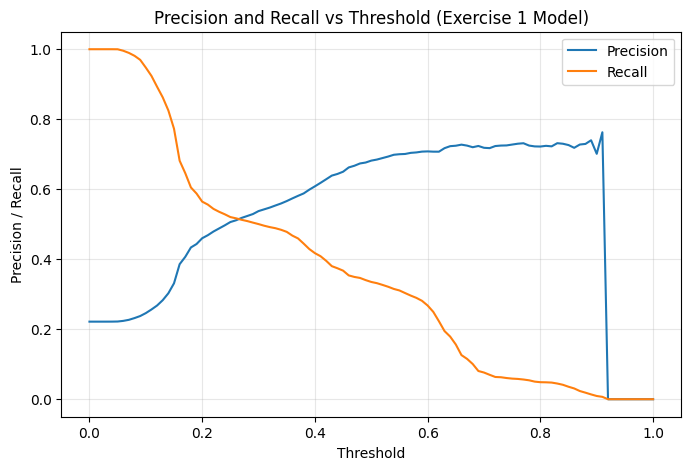

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

df['prob_base'] = model_base.predict(df)

rows = []
for t in np.round(np.arange(0, 1.0001, 0.01), 2):
    pred = (df['prob_base'] >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(df['bad_ar'], pred, labels=[0, 1]).ravel()
    rows.append({'threshold': t,
                 'recall': tp / (tp + fn),
                 'precision': tp / (tp + fp) if (tp + fp) > 0 else 0})
threshold_df = pd.DataFrame(rows)

plt.figure(figsize=(8, 5))
plt.plot(threshold_df['threshold'], threshold_df['precision'], label='Precision')
plt.plot(threshold_df['threshold'], threshold_df['recall'], label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Precision / Recall')
plt.title('Precision and Recall vs Threshold (Exercise 1 Model)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

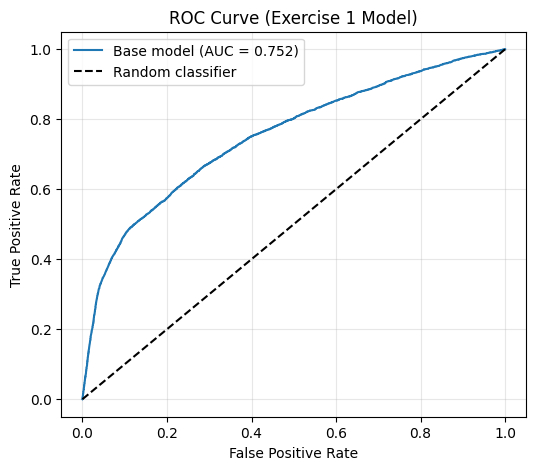

In [4]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, _ = roc_curve(df['bad_ar'], df['prob_base'])
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'Base model (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (Exercise 1 Model)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

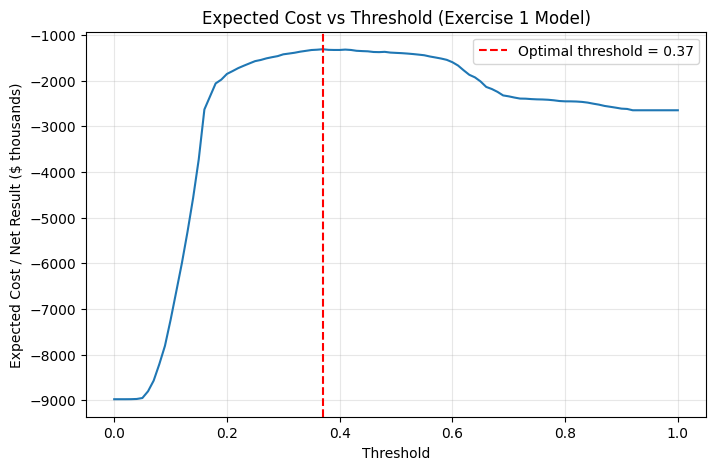

threshold       0.37
net         -1311.80
Name: 37, dtype: float64


In [5]:
TP_BENEFIT, FP_COST, FN_COST = 0.4, 0.5, 0.4   # $ thousands

rows = []
for t in np.round(np.arange(0, 1.0001, 0.01), 2):
    pred = (df['prob_base'] >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(df['bad_ar'], pred, labels=[0, 1]).ravel()
    rows.append({'threshold': t,
                 'net': TP_BENEFIT * tp - FP_COST * fp - FN_COST * fn})
cost_df = pd.DataFrame(rows)

best = cost_df.loc[cost_df['net'].idxmax()]

plt.figure(figsize=(8, 5))
plt.plot(cost_df['threshold'], cost_df['net'])
plt.axvline(best['threshold'], color='r', linestyle='--',
            label=f"Optimal threshold = {best['threshold']:.2f}")
plt.xlabel('Threshold')
plt.ylabel('Expected Cost / Net Result ($ thousands)')
plt.title('Expected Cost vs Threshold (Exercise 1 Model)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(best)